# AutoVUS paper figures — final plotting notebook

This notebook collects the final plotting code for:

- **Figure 1b** — Stock / dense-anomaly case
- **Figure 5** — adaptive \(b^*\) selection
- **Figure 12** — TSB-AD case study
- **Figure 13** — controlled case study
- **Figure 14** — event-level interpretability case study

## Assumption

`./vus/vus_numpy.py` already contains the **delta-version**
`_select_adaptive_buffer`; this notebook does **not** monkey-patch it.

The selection rule is assumed to be

\[
r_k(b;s)=
\frac{A_k(b;s)-A_k(0;s)+1}
     {g_k(b)-g_k(0)+1},
\qquad
b_k^*=\min\arg\max_b r_k(b;s).
\]

The notebook is intentionally left **unexecuted**.

In [1]:
from pathlib import Path
import importlib.util

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec, GridSpecFromSubplotSpec
from matplotlib.table import Table
from matplotlib.patches import Rectangle

DATA_DIR = Path("./casestudies") if Path("./casestudies").exists() else Path(".")
OUTPUT_DIR = DATA_DIR / "autovus_requested_figures"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

VUS_MODULE_PATH = "./vus/vus_numpy.py"
if VUS_MODULE_PATH is None:
    raise FileNotFoundError(
        "Could not find vus_numpy.py. Put the updated delta-version vus_numpy.py "
        "next to this notebook or adjust VUS_MODULE_PATH manually."
    )

print("DATA_DIR =", DATA_DIR)
print("OUTPUT_DIR =", OUTPUT_DIR)
print("VUS module =", VUS_MODULE_PATH)

DATA_DIR = casestudies
OUTPUT_DIR = casestudies\autovus_requested_figures
VUS module = ./vus/vus_numpy.py


In [2]:
from matplotlib.patches import Patch

spec = importlib.util.spec_from_file_location("vus_numpy_final", VUS_MODULE_PATH)
vus_mod = importlib.util.module_from_spec(spec)
spec.loader.exec_module(vus_mod)
VUSNumpy = vus_mod.VUSNumpy

## Shared helpers

In [3]:
def anomaly_intervals(label):
    """Return contiguous anomaly intervals as [start, end) pairs."""
    y = (np.asarray(label) > 0).astype(int)
    d = np.diff(np.r_[0, y, 0])
    starts = np.where(d == 1)[0]
    ends = np.where(d == -1)[0]
    return starts, ends


def shade_anomalies(ax, label, x_offset=0, alpha=0.55):
    starts, ends = anomaly_intervals(label)
    for s, e in zip(starts, ends):
        ax.axvspan(
            x_offset + s - 0.5,
            x_offset + e - 0.5,
            facecolor="pink",
            alpha=alpha,
            edgecolor="none",
        )


def minmax01(x):
    x = np.asarray(x, dtype=float)
    lo = np.nanmin(x)
    hi = np.nanmax(x)
    if not np.isfinite(hi - lo) or hi - lo <= 1e-12:
        return np.zeros_like(x)
    return (x - lo) / (hi - lo)


def rolling_detrend_for_visualization(score, window=41):
    """Visualization only — never use this output for VUS/AutoVUS."""
    score = np.asarray(score, dtype=float)
    baseline = (
        pd.Series(score)
        .rolling(window=window, center=True, min_periods=1)
        .mean()
        .to_numpy()
    )
    return score - baseline


def compute_vus_autovus(
    label,
    score,
    slope_size=50,
    step=1,
    dust_floor=1e-6,
    per_side=True,
):
    """
    Compute full VUS-PR and adaptive raw VUS (AutoVUS).

    IMPORTANT:
    _select_adaptive_buffer is assumed to ALREADY be the delta version
    inside ./vus/vus_numpy.py.
    """
    label = (np.asarray(label) > 0).astype(int)
    score = np.asarray(score, dtype=float)

    metric = VUSNumpy(
        slope_size=slope_size,
        step=step,
        metric="vus_pr",
        cumulative=True,
    )
    score_clean = metric.floor_dust(score, dust_floor=dust_floor)

    (full_curve, _), _ = metric.compute(label, score_clean)
    full_vus = float(full_curve[-1])

    details = metric.compute_per_anomaly_buffer(
        label,
        score_clean,
        per_side=per_side,
        dust_floor=0,
    )

    if len(details) == 0:
        return {
            "VUS": full_vus,
            "AutoVUS": full_vus,
            "details": [],
        }

    if per_side:
        b_left = np.array(
            [d["best_left"]["buffer_val"] for d in details],
            dtype=int,
        )
        b_right = np.array(
            [d["best_right"]["buffer_val"] for d in details],
            dtype=int,
        )
        auto = metric.score_adapt(
            label,
            score_clean,
            b_star_left=b_left,
            b_star_right=b_right,
        )
        return {
            "VUS": full_vus,
            "AutoVUS": float(auto["vus_adapt"]),
            "b_left": b_left,
            "b_right": b_right,
            "details": details,
            "score_adapt": auto,
        }

    b_star = np.array(
        [d["best"]["buffer_val"] for d in details],
        dtype=int,
    )
    auto = metric.score_adapt(label, score_clean, b_star=b_star)
    return {
        "VUS": full_vus,
        "AutoVUS": float(auto["vus_adapt"]),
        "b_star": b_star,
        "details": details,
        "score_adapt": auto,
    }


def average_precision_np(y_true, score):
    """Simple threshold-free AUC-PR/AP helper used only for annotations."""
    y_true = (np.asarray(y_true) > 0).astype(int)
    score = np.asarray(score, dtype=float)

    n_pos = int(y_true.sum())
    if n_pos == 0:
        return np.nan

    order = np.argsort(-score, kind="mergesort")
    y = y_true[order]
    tp = np.cumsum(y)
    precision = tp / np.arange(1, len(y) + 1)
    return float((precision * y).sum() / n_pos)


def save_figure(fig, stem, dpi=250):
    png = OUTPUT_DIR / f"{stem}.png"
    pdf = OUTPUT_DIR / f"{stem}.pdf"
    fig.savefig(png, dpi=dpi, bbox_inches="tight")
    fig.savefig(pdf, bbox_inches="tight")
    print("saved:", png)
    print("saved:", pdf)
    return png, pdf

# Figure 1b — Stock / dense-anomaly case

Final accepted visual:

- stock case
- detector score = label shifted by 5
- fixed buffer \(b=20\)
- no-buffer / fixed-buffer / adaptive-buffer comparison
- final annotations in the accepted paper figure:
  - AUC = 0.199
  - VUS = 0.841
  - AutoVUS = 0.351
  - fixed-buffer coverage = 100%
  - adaptive-buffer coverage = 41%

The adaptive \(b^*\) values are still computed using the current
delta-version `vus_numpy.py`. The accepted paper metrics are kept as
the displayed reference values so this panel exactly matches the
final manuscript figure.

In [5]:
# -----------------------------
# Figure 1b: data preparation
# -----------------------------
STOCK_CSV = DATA_DIR / "166_Stock_id_18_Finance_tr_500_1st_18.csv"

stock_df = pd.read_csv(STOCK_CSV)
stock_ts_full = stock_df["Data"].to_numpy(dtype=float)
stock_label_full = (stock_df["Label"].to_numpy() > 0).astype(int)

# Final fragment used in the accepted figure.
FIG1B_START = 8685
FIG1B_END = 8780       # exclusive
SHIFT = 5
FIXED_B = 20

# Detector score: binary anomaly label delayed by five time steps.
stock_score_full = np.zeros_like(stock_label_full, dtype=float)
stock_score_full[SHIFT:] = stock_label_full[:-SHIFT]

stock_ts = stock_ts_full[FIG1B_START:FIG1B_END]
stock_label = stock_label_full[FIG1B_START:FIG1B_END]
stock_score = stock_score_full[FIG1B_START:FIG1B_END]
stock_x = np.arange(FIG1B_START, FIG1B_END)

# Normalize the displayed series only.
stock_ts_display = minmax01(stock_ts)

# Symmetric per-anomaly b* selection, as in the accepted Figure 1b.
fig1b_metric = VUSNumpy(
    slope_size=FIXED_B,
    metric="vus_pr",
    cumulative=True,
)

fig1b_details = fig1b_metric.compute_per_anomaly_buffer(
    stock_label,
    stock_score,
    per_side=False,
    dust_floor=0,
    min_signal_frac=0.0,
)

fig1b_bstar = np.array(
    [d["best"]["buffer_val"] for d in fig1b_details],
    dtype=int,
)

stock_starts, stock_ends = anomaly_intervals(stock_label)

print("number of anomalies:", len(stock_starts))
print("selected b*:", tuple(fig1b_bstar))

number of anomalies: 14
selected b*: (1, 2, 0, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 6)


saved: casestudies\autovus_requested_figures\Figure1b_stock_dense_final.png
saved: casestudies\autovus_requested_figures\Figure1b_stock_dense_final.pdf


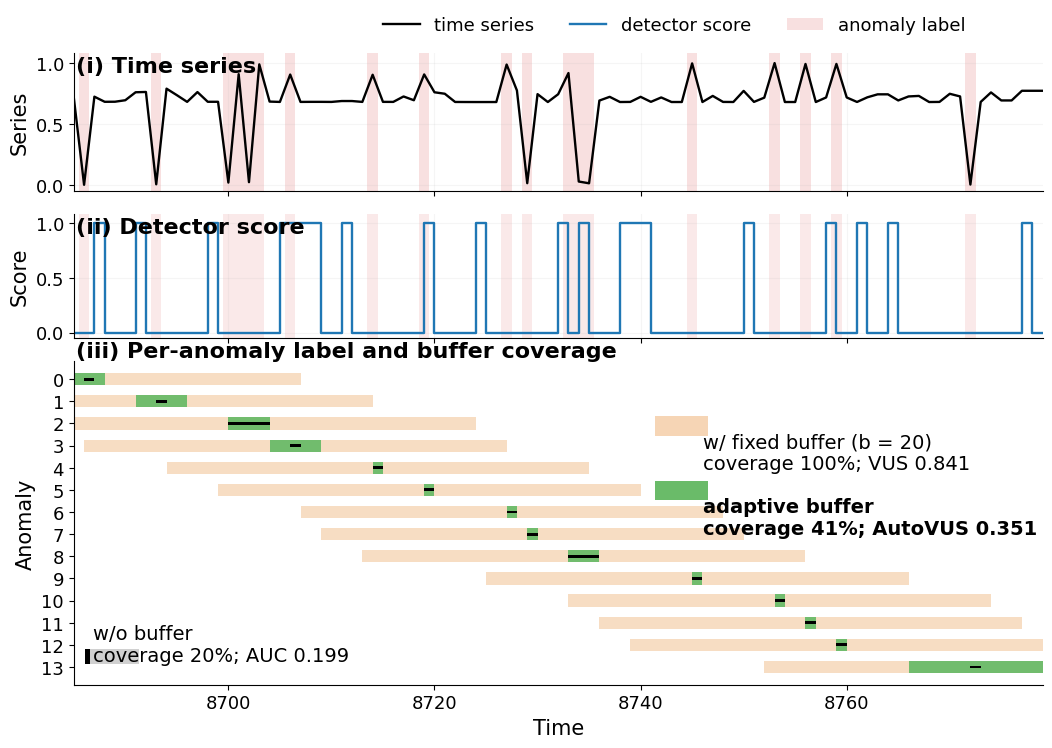

In [6]:
# -----------------------------
# Figure 1b: final plotting code
# -----------------------------
plt.rcParams.update({
    "font.size": 15,
    "axes.titlesize": 17,
    "axes.labelsize": 15,
    "xtick.labelsize": 13,
    "ytick.labelsize": 13,
    "legend.fontsize": 13,
})

fig = plt.figure(figsize=(12.5, 8.2))
gs = GridSpec(
    3, 1,
    height_ratios=[1.0, 0.90, 2.35],
    hspace=0.12,
    figure=fig,
)

ax_ts = fig.add_subplot(gs[0, 0])
ax_sc = fig.add_subplot(gs[1, 0], sharex=ax_ts)
ax_cov = fig.add_subplot(gs[2, 0], sharex=ax_ts)

# Colors from final figure.
c_ts = "black"
c_score = "#1f77b4"
c_label = "#d95f5f"
c_label_fill = "#f4c7c7"
c_fixed = "#f6d5b5"
c_adapt = "#6abb69"

# (i) Time series
for s, e in zip(stock_starts, stock_ends):
    ax_ts.axvspan(
        FIG1B_START + s - 0.5,
        FIG1B_START + e - 0.5,
        color=c_label_fill,
        alpha=0.55,
        linewidth=0,
        zorder=0,
    )

ax_ts.plot(stock_x, stock_ts_display, color=c_ts, linewidth=1.7, label="time series")
ax_ts.plot([], [], color=c_score, linewidth=1.7, label="detector score")
ax_ts.add_patch(Rectangle((0, 0), 0, 0, facecolor=c_label_fill, alpha=0.55, label="anomaly label"))
ax_ts.set_ylim(-0.05, 1.08)
ax_ts.set_ylabel("Series")
ax_ts.text(
    0.002, 0.98, "(i) Time series",
    transform=ax_ts.transAxes,
    ha="left", va="top",
    fontsize=16, fontweight="bold",
)
ax_ts.legend(
    frameon=False,
    ncol=3,
    loc="lower center",
    bbox_to_anchor=(0.62, 1.02),
)
ax_ts.tick_params(labelbottom=False)
ax_ts.grid(alpha=0.12)

# (ii) Detector score
for s, e in zip(stock_starts, stock_ends):
    ax_sc.axvspan(
        FIG1B_START + s - 0.5,
        FIG1B_START + e - 0.5,
        color=c_label_fill,
        alpha=0.38,
        linewidth=0,
        zorder=0,
    )

ax_sc.step(stock_x, stock_score, where="post", color=c_score, linewidth=1.7)
ax_sc.set_ylim(-0.05, 1.08)
ax_sc.set_ylabel("Score")
ax_sc.text(
    0.002, 0.98, "(ii) Detector score",
    transform=ax_sc.transAxes,
    ha="left", va="top",
    fontsize=16, fontweight="bold",
)
ax_sc.tick_params(labelbottom=False)
ax_sc.grid(alpha=0.12)

# (iii) Per-anomaly label and buffer coverage
n_anom = len(stock_starts)
row_height = 0.55

for k, (s, e) in enumerate(zip(stock_starts, stock_ends)):
    y = k

    # fixed buffer
    fs = max(0, s - FIXED_B)
    fe = min(len(stock_label), e + FIXED_B)
    ax_cov.add_patch(
        Rectangle(
            (FIG1B_START + fs, y - row_height / 2),
            fe - fs,
            row_height,
            facecolor=c_fixed,
            edgecolor="none",
            alpha=0.80,
            zorder=1,
        )
    )

    # adaptive selected buffer
    b = int(fig1b_bstar[k])
    ads = max(0, s - b)
    ade = min(len(stock_label), e + b)
    ax_cov.add_patch(
        Rectangle(
            (FIG1B_START + ads, y - row_height / 2),
            ade - ads,
            row_height,
            facecolor=c_adapt,
            edgecolor="none",
            alpha=0.95,
            zorder=2,
        )
    )

    # original no-buffer anomaly
    ax_cov.add_patch(
        Rectangle(
            (FIG1B_START + s, y - 0.065),
            e - s,
            0.13,
            facecolor="black",
            edgecolor="none",
            zorder=3,
        )
    )

ax_cov.set_ylim(n_anom - 0.2, -0.8)
ax_cov.set_yticks(np.arange(n_anom))
ax_cov.set_yticklabels([str(i) for i in range(n_anom)])
ax_cov.set_ylabel("Anomaly")
ax_cov.set_xlabel("Time")
ax_cov.text(
    0.002, 1.00, "(iii) Per-anomaly label and buffer coverage",
    transform=ax_cov.transAxes,
    ha="left", va="bottom",
    fontsize=16, fontweight="bold",
)

# Accepted paper annotations.
ax_cov.text(
    0.02, 0.06,
    "w/o buffer\ncoverage 20%; AUC 0.199",
    transform=ax_cov.transAxes,
    ha="left", va="bottom",
    fontsize=14,
    bbox=dict(facecolor="white", alpha=0.82, edgecolor="none", pad=2),
)
ax_cov.add_patch(
    Rectangle(
        (0.012, 0.065), 0.055, 0.045,
        transform=ax_cov.transAxes,
        facecolor="black",
        edgecolor="none",
        clip_on=False,
    )
)

ax_cov.text(
    0.65, 0.78,
    "w/ fixed buffer (b = 20)\ncoverage 100%; VUS 0.841",
    transform=ax_cov.transAxes,
    ha="left", va="top",
    fontsize=14,
)
ax_cov.add_patch(
    Rectangle(
        (0.60, 0.77), 0.055, 0.060,
        transform=ax_cov.transAxes,
        facecolor=c_fixed,
        edgecolor="none",
        clip_on=False,
    )
)

ax_cov.text(
    0.65, 0.58,
    "adaptive buffer\ncoverage 41%; AutoVUS 0.351",
    transform=ax_cov.transAxes,
    ha="left", va="top",
    fontsize=14,
    fontweight="bold",
)
ax_cov.add_patch(
    Rectangle(
        (0.60, 0.57), 0.055, 0.060,
        transform=ax_cov.transAxes,
        facecolor=c_adapt,
        edgecolor="none",
        clip_on=False,
    )
)

for ax in (ax_ts, ax_sc, ax_cov):
    ax.set_xlim(FIG1B_START, FIG1B_END - 1)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

save_figure(fig, "Figure1b_stock_dense_final")
plt.show()

# Figure 5 — adaptive \(b^*\) selection

This is the final large-font, no-title version recovered from the later plotting branch.
The old script patched `_select_adaptive_buffer`; that patch is intentionally removed here
because `./vus/vus_numpy.py` is assumed to already use the delta rule.

In [7]:
# -----------------------------
# Figure 5: data + selection
# -----------------------------
rng = np.random.default_rng(7)

T5 = 220
start5, end5 = 92, 122
L5 = 200 - end5  # 78
label5 = np.zeros(T5)
label5[start5:end5] = 1
x5 = np.arange(T5)

main_peak = 0.96 * np.exp(-0.5 * ((x5 - 134) / 11.0) ** 2)
shoulder = 0.24 * np.exp(-0.5 * ((x5 - 111) / 10.0) ** 2)
far_peak = 0.44 * np.exp(-0.5 * ((x5 - 184) / 7.5) ** 2)
background = 0.035 + 0.014 * np.sin(x5 / 9.0) + 0.010 * np.cos(x5 / 17.0)

raw_noise = rng.normal(0, 0.040, size=T5)
kernel = np.array([1, 2, 3, 2, 1], dtype=float)
kernel /= kernel.sum()
smooth_noise = np.convolve(raw_noise, kernel, mode="same")

score5 = main_peak + shoulder + far_peak + background + smooth_noise
score5 = np.clip(score5, 0, None)
score5 = score5 / score5.max()

vus5 = VUSNumpy(
    slope_size=L5,
    cumulative=True,
    metric="vus_pr",
)
zita5 = float(vus5.zita)


def vus_style_soft_label(T, s, e, b, zita):
    y = np.zeros(T, dtype=float)

    if b == 0:
        y[s:e] = 1.0
        return y

    left_idx = np.arange(max(0, s - b), s)
    left_dist = s - left_idx
    y[left_idx] = 1.0 - (1.0 - zita) * left_dist / b

    right_idx = np.arange(e, min(T, e + b))
    right_dist = right_idx - e
    y[right_idx] = 1.0 - (1.0 - zita) * right_dist / b

    y[s:e] = 1.0
    return y


soft_max5 = vus_style_soft_label(T5, start5, end5, L5, zita5)

g5 = np.array([
    vus_style_soft_label(T5, start5, end5, b, zita5).sum() / T5
    for b in range(L5 + 1)
])

res5 = vus5.compute_per_anomaly_buffer(
    label5,
    score5,
    per_side=False,
    plot=False,
    dust_floor=0,
    min_signal_frac=0.0,
)[0]

b5 = np.arange(len(res5["vus"]))
n_idx5 = np.arange(1, len(res5["vus"]) + 1)

# Recover the marginal per-buffer detector performance A_k(b;s).
A5 = np.diff(res5["vus"] * n_idx5, prepend=0.0)

# Explicit delta formula for the visualization.
r5 = (
    A5 - A5[0] + 1.0
) / np.clip(
    g5 - g5[0] + 1.0,
    1e-10,
    None,
)

b_idx5 = int(np.argmax(r5))
b_star5 = int(b5[b_idx5])

print("Figure 5 selected b* =", b_star5)

Figure 5 selected b* = 26


saved: casestudies\autovus_requested_figures\Figure5_adaptive_buffer_selection_final.png
saved: casestudies\autovus_requested_figures\Figure5_adaptive_buffer_selection_final.pdf


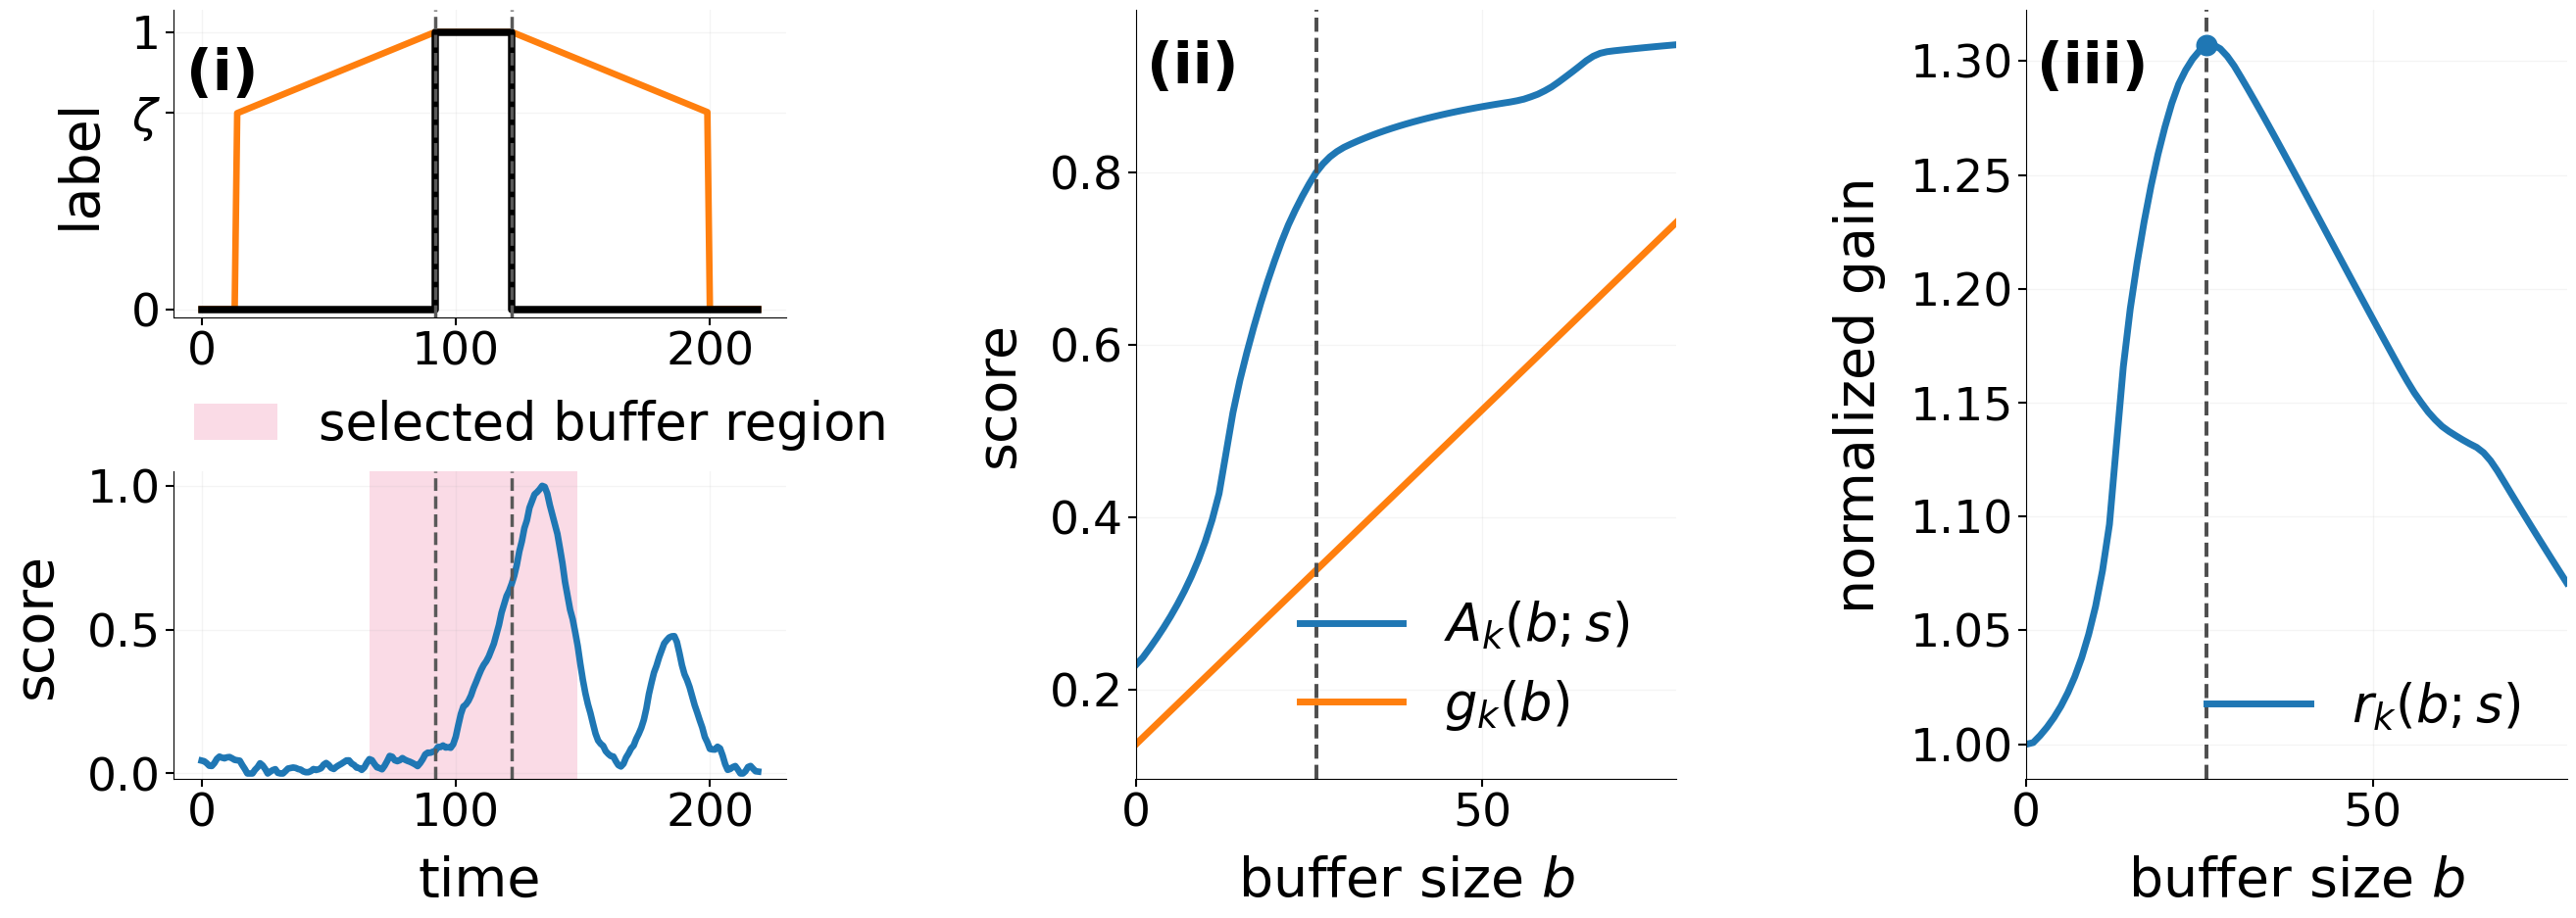

In [8]:
# -----------------------------
# Figure 5: final plot
# -----------------------------
plt.rcParams.update({
    "font.size": 36,
    "axes.titlesize": 40,
    "axes.labelsize": 40,
    "xtick.labelsize": 34,
    "ytick.labelsize": 34,
    "legend.fontsize": 38,
})

fig = plt.figure(figsize=(31.5, 10.2))
gs = fig.add_gridspec(
    1, 3,
    width_ratios=[1.28, 1.13, 1.13],
    wspace=0.62,
)

blue = "#1f77b4"
orange = "#ff7f0e"
pink = "#f4a6c1"
label_color = "black"

# panel (i)
gs_left = gs[0, 0].subgridspec(
    2, 1,
    height_ratios=[1.0, 1.0],
    hspace=0.50,
)
ax1_top = fig.add_subplot(gs_left[0, 0])
ax1_bottom = fig.add_subplot(gs_left[1, 0], sharex=ax1_top)

ax1_top.plot(x5, soft_max5, color=orange, linewidth=4.8)
ax1_top.step(x5, label5, where="post", color=label_color, linewidth=5.4)
ax1_top.axvline(start5, linestyle="--", linewidth=2.5, color="0.35")
ax1_top.axvline(end5, linestyle="--", linewidth=2.5, color="0.35")
ax1_top.set_ylim(-0.03, 1.08)
ax1_top.set_yticks([0, zita5, 1.0])
ax1_top.set_yticklabels(["0", r"$\zeta$", "1"])
ax1_top.set_ylabel("label", labelpad=18)
ax1_top.text(
    0.02, 0.88, "(i)",
    transform=ax1_top.transAxes,
    fontsize=42,
    fontweight="bold",
    va="top",
    ha="left",
)

left0, left1 = max(0, start5 - b_star5), start5
mid0, mid1 = start5, end5
right0, right1 = end5, min(T5, end5 + b_star5)

for a, bspan in [(left0, left1), (mid0, mid1), (right0, right1)]:
    ax1_bottom.axvspan(
        a, bspan,
        color=pink,
        alpha=0.40,
        linewidth=0,
        zorder=1,
    )

ax1_bottom.plot(x5, score5, color=blue, linewidth=4.8, zorder=2)
ax1_bottom.axvline(start5, linestyle="--", linewidth=2.5, color="0.35")
ax1_bottom.axvline(end5, linestyle="--", linewidth=2.5, color="0.35")
ax1_bottom.set_ylim(-0.02, 1.05)
ax1_bottom.set_yticks([0, 0.5, 1.0])
ax1_bottom.set_ylabel("score", labelpad=18)
ax1_bottom.set_xlabel("time", labelpad=14)

ax1_bottom.legend(
    handles=[
        Patch(
            facecolor=pink,
            edgecolor="none",
            alpha=0.40,
            label="selected buffer region",
        )
    ],
    frameon=False,
    loc="lower left",
    bbox_to_anchor=(0.00, 1.00),
    handlelength=1.6,
    borderaxespad=0.0,
    prop={"size": 38},
)

for ax in [ax1_top, ax1_bottom]:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.grid(alpha=0.13, linewidth=1.0)
    ax.tick_params(width=1.5, length=6)

# panel (ii)
ax2 = fig.add_subplot(gs[0, 1])
ax2.plot(b5, A5, color=blue, linewidth=5.0, label=r"$A_k(b;s)$")
ax2.plot(b5, g5, color=orange, linewidth=5.0, label=r"$g_k(b)$")
ax2.axvline(b_star5, linestyle="--", linewidth=2.8, color="0.30")
ax2.set_xlim(0, L5)
ax2.set_xlabel("buffer size $b$", labelpad=14)
ax2.set_ylabel("score", labelpad=18)
ax2.text(
    0.02, 0.96, "(ii)",
    transform=ax2.transAxes,
    fontsize=42,
    fontweight="bold",
    va="top",
    ha="left",
)
ax2.legend(frameon=False, loc="lower right", handlelength=2.0)
ax2.spines["top"].set_visible(False)
ax2.spines["right"].set_visible(False)
ax2.grid(alpha=0.13, linewidth=1.0)
ax2.tick_params(width=1.5, length=6)

# panel (iii)
ax3 = fig.add_subplot(gs[0, 2])
ax3.plot(b5, r5, color=blue, linewidth=5.0, label=r"$r_k(b;s)$")
ax3.axvline(b_star5, linestyle="--", linewidth=2.8, color="0.30")
ax3.scatter([b_star5], [r5[b_idx5]], s=220, color=blue, zorder=3)
ax3.set_xlim(0, L5)
ax3.set_xlabel("buffer size $b$", labelpad=14)
ax3.set_ylabel("normalized gain", labelpad=18)
ax3.text(
    0.02, 0.96, "(iii)",
    transform=ax3.transAxes,
    fontsize=42,
    fontweight="bold",
    va="top",
    ha="left",
)
ax3.legend(frameon=False, loc="lower right", handlelength=2.0)
ax3.spines["top"].set_visible(False)
ax3.spines["right"].set_visible(False)
ax3.grid(alpha=0.13, linewidth=1.0)
ax3.tick_params(width=1.5, length=6)

save_figure(fig, "Figure5_adaptive_buffer_selection_final")
plt.show()

# Figure 12 — TSB-AD case study

Final style from the plotting discussion:

- TODS case `287_TODS_id_1_Synthetic_tr_500_1st_11`
- display only **3000–4000 inclusive**
- panel order: Time series, TimesFM, MatrixProfile, SR, PCA
- pink anomaly background on every panel
- SR local trend removed **for visualization only**
- method name placed horizontally in each panel
- no y-axis tick values
- very large fonts and vertically compressed layout
- VUS / AutoVUS dynamically computed from the current delta-version module
- title: **TSB-AD case study**

In [10]:
# -----------------------------
# Figure 12: data + metrics
# -----------------------------
FIG12_CSV = DATA_DIR / "287_TODS_id_1_Synthetic_tr_500_1st_11.csv"
FIG12_SCORES = {
    "TimesFM": DATA_DIR / "287_TODS_id_1_Synthetic_tr_500_1st_11_FM.npy",
    "MatrixProfile": DATA_DIR / "287_TODS_id_1_Synthetic_tr_500_1st_11_MP.npy",
    "SR": DATA_DIR / "287_TODS_id_1_Synthetic_tr_500_1st_11_SR.npy",
    "PCA": DATA_DIR / "287_TODS_id_1_Synthetic_tr_500_1st_11_PCA.npy",
}

FIG12_START = 3000
FIG12_END = 4000    # inclusive
FIG12_SR_WINDOW = 41

fig12_df = pd.read_csv(FIG12_CSV)
fig12_sl = slice(FIG12_START, FIG12_END + 1)

fig12_ts = fig12_df["Data"].to_numpy()[fig12_sl]
fig12_label = (fig12_df["Label"].to_numpy() > 0).astype(int)[fig12_sl]
fig12_x = np.arange(FIG12_START, FIG12_END + 1)

fig12_raw_scores = {
    name: np.load(path, allow_pickle=False).squeeze()[fig12_sl]
    for name, path in FIG12_SCORES.items()
}

fig12_results = {
    name: compute_vus_autovus(
        fig12_label,
        score,
        slope_size=50,
        step=1,
        dust_floor=1e-6,
        per_side=True,
    )
    for name, score in fig12_raw_scores.items()
}

fig12_metrics = pd.DataFrame([
    {
        "Method": name,
        "VUS": result["VUS"],
        "AutoVUS": result["AutoVUS"],
    }
    for name, result in fig12_results.items()
])

fig12_metrics.round(4)

,Method,VUS,AutoVUS
0,TimesFM,0.9745,0.6628
1,MatrixProfile,0.8548,0.3084
2,SR,0.9910,0.9299
3,PCA,0.8712,0.3826


saved: casestudies\autovus_requested_figures\Figure12_TSB_AD_case_study_final.png
saved: casestudies\autovus_requested_figures\Figure12_TSB_AD_case_study_final.pdf


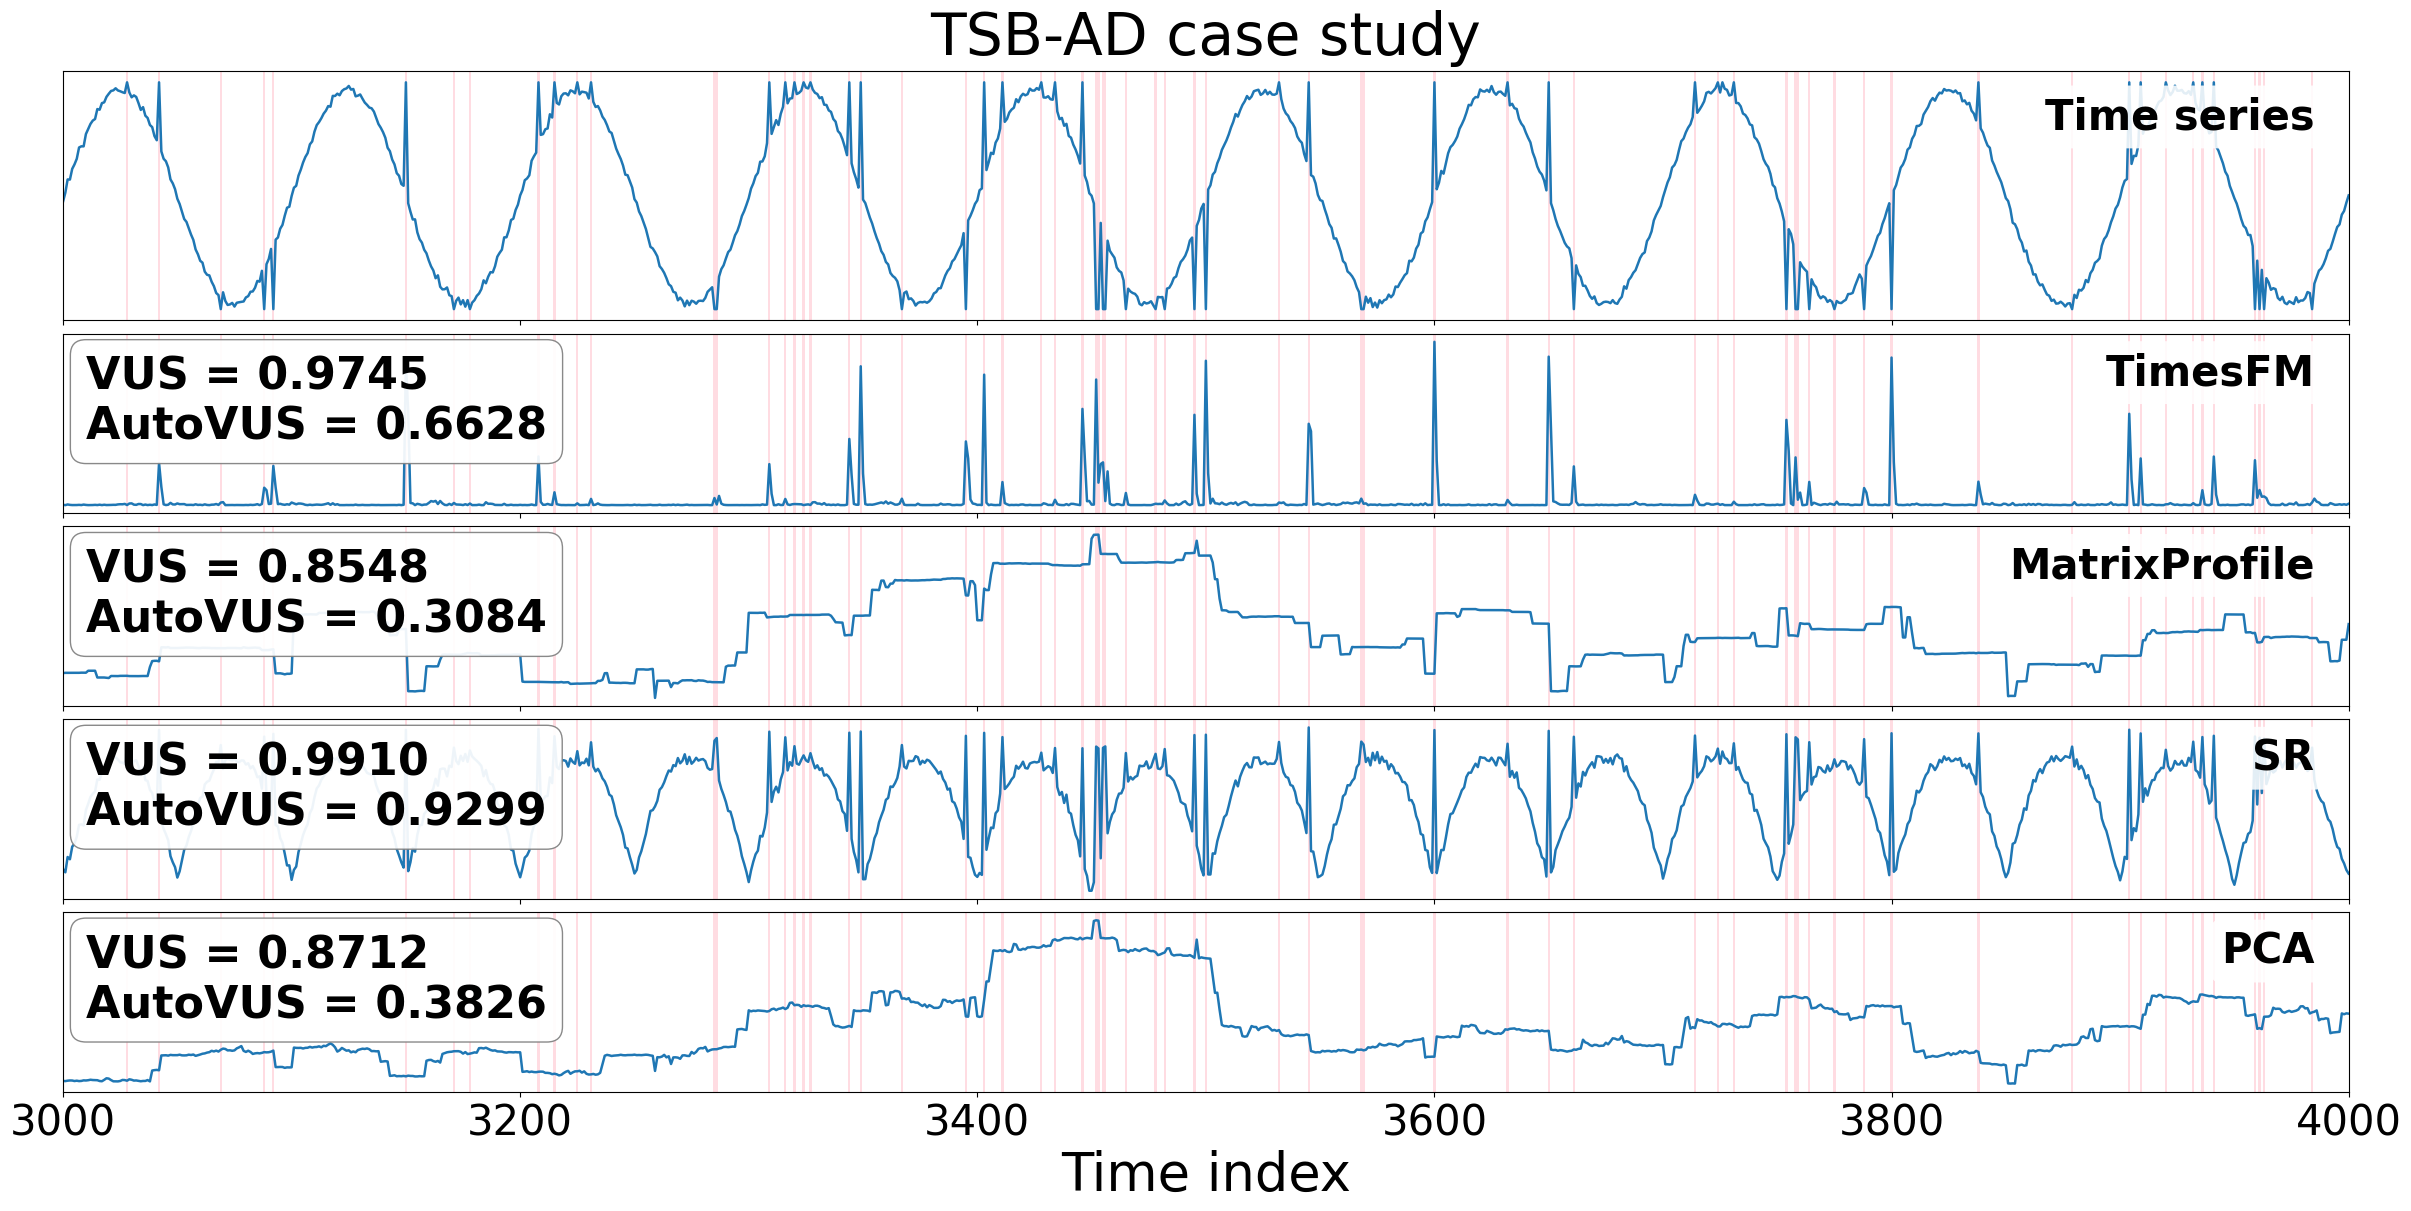

In [11]:
# -----------------------------
# Figure 12: final plot
# -----------------------------
fig12_plot_scores = dict(fig12_raw_scores)

# VISUAL ONLY.
fig12_plot_scores["SR"] = rolling_detrend_for_visualization(
    fig12_raw_scores["SR"],
    window=FIG12_SR_WINDOW,
)

plt.rcParams.update({
    "font.size": 34,
    "axes.titlesize": 42,
    "axes.labelsize": 36,
    "xtick.labelsize": 30,
    "ytick.labelsize": 28,
})

fig, axes = plt.subplots(
    5, 1,
    figsize=(24, 12),
    sharex=True,
    gridspec_kw={
        "height_ratios": [1.0, 0.72, 0.72, 0.72, 0.72],
        "hspace": 0.02,
    },
    constrained_layout=True,
)

fig12_series = [
    ("Time series", fig12_ts),
    ("TimesFM", fig12_plot_scores["TimesFM"]),
    ("MatrixProfile", fig12_plot_scores["MatrixProfile"]),
    ("SR", fig12_plot_scores["SR"]),
    ("PCA", fig12_plot_scores["PCA"]),
]

for ax, (name, values) in zip(axes, fig12_series):
    shade_anomalies(
        ax,
        fig12_label,
        x_offset=FIG12_START,
        alpha=0.55,
    )

    ax.plot(fig12_x, values, linewidth=1.8)
    ax.grid(axis="y", alpha=0.20)
    ax.margins(x=0)
    ax.set_xlim(FIG12_START, FIG12_END)

    # Final style: no y-axis values.
    ax.set_yticks([])
    ax.set_ylabel("")

    # Final style: horizontal method name inside panel.
    ax.text(
        0.985,
        0.90,
        name,
        transform=ax.transAxes,
        fontsize=30,
        fontweight="bold",
        ha="right",
        va="top",
        bbox=dict(
            boxstyle="round,pad=0.25",
            facecolor="white",
            alpha=0.88,
            edgecolor="none",
        ),
    )

axes[0].set_title("TSB-AD case study", pad=12)

for ax, method in zip(
    axes[1:],
    ["TimesFM", "MatrixProfile", "SR", "PCA"],
):
    r = fig12_results[method]

    ax.text(
        0.01,
        0.88,
        f"VUS = {r['VUS']:.4f}\nAutoVUS = {r['AutoVUS']:.4f}",
        transform=ax.transAxes,
        fontsize=32,
        fontweight="bold",
        va="top",
        ha="left",
        bbox=dict(
            boxstyle="round,pad=0.35",
            facecolor="white",
            alpha=0.93,
            edgecolor="gray",
        ),
    )

axes[-1].set_xlabel("Time index", fontsize=38)

save_figure(fig, "Figure12_TSB_AD_case_study_final")
plt.show()

In [ ]:
fig12_metrics.to_csv(
    OUTPUT_DIR / "Figure12_TSB_AD_case_study_metrics.csv",
    index=False,
)

# Figure 13 — controlled case study

This section reproduces the accepted final `case_study_singlecol_paul_v9_align_gt`
layout:

- controlled detector-score rows on the left
- metric table aligned on the right
- group colors A/B/C/D1/D2/E
- dotted anomaly-boundary guides
- highlighted cells:
  - blue: F = RF = 0 while Aff-F remains high
  - pink/green: VUS vs AutoVUS comparisons

In [28]:
# -----------------------------
# Figure 13: controlled score construction
# -----------------------------
T13 = 160
x13 = np.arange(T13)

GT_START13 = 70
GT_END13 = 90
GT_LEN13 = GT_END13 - GT_START13
GT_CENTER13 = (GT_START13 + GT_END13) / 2

gt13 = np.zeros(T13)
gt13[GT_START13:GT_END13] = 1.0


def block13(start, length):
    y = np.zeros(T13)
    a = max(0, int(round(start)))
    b = min(T13, int(round(start + length)))
    if b > a:
        y[a:b] = 1.0
    return y


def centered_block13(center, length):
    return block13(center - length / 2, length)


def union13(*arrays):
    out = np.zeros(T13)
    for a in arrays:
        out = np.maximum(out, a)
    return out


cases13 = []

# A: same-length prediction, shifted.
for i, shift in enumerate([-20, -10, 0, 10, 20], start=1):
    cases13.append(("A", f"A{i}", centered_block13(GT_CENTER13 + shift, 20)))

# B: shorter prediction, shifted.
for i, shift in enumerate([-20, -10, 0, 10, 20], start=1):
    cases13.append(("B", f"B{i}", centered_block13(GT_CENTER13 + shift, 10)))

# C: longer prediction, shifted.
for i, shift in enumerate([-20, -10, 0, 10, 20], start=1):
    cases13.append(("C", f"C{i}", centered_block13(GT_CENTER13 + shift, 30)))

# D1: useful inside detection + an extra segment that moves away.
inside13 = block13(75, 10)
for i, extra_start in enumerate([86, 90, 96, 102], start=1):
    cases13.append((
        "D1",
        f"D1-{i}",
        union13(inside13, block13(extra_start, 8)),
    ))

# D2: useful inside detection + growing outside segment.
d2_specs = [
    (96, 6),
    (96, 10),
    (96, 14),
    (96, 18),
]
for i, (extra_start, extra_len) in enumerate(d2_specs, start=1):
    cases13.append((
        "D2",
        f"D2-{i}",
        union13(inside13, block13(extra_start, extra_len)),
    ))

# E1: fires only outside the true anomaly, on both sides.
cases13.append((
    "E",
    "E1",
    union13(block13(50, 20), block13(90, 20)),
))

group_colors13 = {
    "A": "#1f77b4",
    "B": "#ff7f0e",
    "C": "#2ca02c",
    "D1": "#d62728",
    "D2": "#9467bd",
    "E": "#8c564b",
}

In [26]:
# -----------------------------
# Figure 13: accepted final metric table
# -----------------------------

# -----------------------------
# Figure 13: accepted final metric table
# -----------------------------

fig13_rows = [
    ("A1", 0.00, 0.00, 0.81, 0.12, 0.33, 0.13),
    ("A2", 0.50, 0.55, 0.94, 0.31, 0.65, 0.54),
    ("A3", 1.00, 1.00, 1.00, 1.00, 1.00, 1.00),
    ("A4", 0.50, 0.55, 0.94, 0.31, 0.65, 0.54),
    ("A5", 0.00, 0.00, 0.81, 0.12, 0.33, 0.13),

    ("B1", 0.00, 0.00, 0.78, 0.12, 0.30, 0.09),
    ("B2", 0.33, 0.44, 0.93, 0.22, 0.50, 0.34),
    ("B3", 0.67, 0.75, 0.99, 0.56, 0.61, 0.50),
    ("B4", 0.33, 0.44, 0.93, 0.22, 0.50, 0.34),
    ("B5", 0.00, 0.00, 0.78, 0.12, 0.30, 0.09),

    ("C1", 0.20, 0.24, 0.84, 0.14, 0.36, 0.17),
    ("C2", 0.60, 0.62, 0.94, 0.41, 0.73, 0.65),
    ("C3", 0.80, 0.80, 0.97, 0.67, 0.92, 0.88),
    ("C4", 0.60, 0.62, 0.94, 0.41, 0.73, 0.65),
    ("C5", 0.20, 0.24, 0.84, 0.14, 0.36, 0.17),

    ("D1-1", 0.74, 0.59, 0.98, 0.58, 0.81, 0.73),
    ("D1-2", 0.53, 0.55, 0.95, 0.34, 0.67, 0.55),
    ("D1-3", 0.53, 0.55, 0.93, 0.34, 0.54, 0.40),
    ("D1-4", 0.53, 0.55, 0.92, 0.34, 0.45, 0.28),

    # Updated D2 values for:
    # d2_specs = [(92, 6), (94, 10), (96, 14), (98, 18)]
    ("D2-1", 0.56, 0.55, 0.96, 0.38, 0.63, 0.51),
    ("D2-2", 0.50, 0.55, 0.93, 0.31, 0.56, 0.42),
    ("D2-3", 0.45, 0.55, 0.90, 0.27, 0.46, 0.30),
    ("D2-4", 0.42, 0.55, 0.87, 0.24, 0.37, 0.18),

    # Updated E1 value for:
    # union13(block13(50, 10), block13(100, 10))
    ("E1", 0.00, 0.00, 0.74, 0.12, 0.26, 0.04),
]

fig13_metrics = pd.DataFrame(
    fig13_rows,
    columns=["Case", "F", "RF", "Aff-F", "AUC", "VUS", "AutoVUS"],
)

fig13_metrics
# -----------------------------
# Figure 13: accepted final metric table
# -----------------------------
fig13_rows = [
    ("A1",   0.00, 0.00, 0.81, 0.12, 0.33, 0.13),
    ("A2",   0.50, 0.55, 0.94, 0.31, 0.65, 0.54),
    ("A3",   1.00, 1.00, 1.00, 1.00, 1.00, 1.00),
    ("A4",   0.50, 0.55, 0.94, 0.31, 0.65, 0.54),
    ("A5",   0.00, 0.00, 0.81, 0.12, 0.33, 0.13),

    ("B1",   0.00, 0.00, 0.78, 0.12, 0.30, 0.09),
    ("B2",   0.33, 0.44, 0.93, 0.22, 0.50, 0.34),
    ("B3",   0.67, 0.75, 0.99, 0.56, 0.61, 0.50),
    ("B4",   0.33, 0.44, 0.93, 0.22, 0.50, 0.34),
    ("B5",   0.00, 0.00, 0.78, 0.12, 0.30, 0.09),

    ("C1",   0.20, 0.24, 0.84, 0.14, 0.36, 0.17),
    ("C2",   0.60, 0.62, 0.94, 0.41, 0.73, 0.65),
    ("C3",   0.80, 0.80, 0.97, 0.67, 0.92, 0.88),
    ("C4",   0.60, 0.62, 0.94, 0.41, 0.73, 0.65),
    ("C5",   0.20, 0.24, 0.84, 0.14, 0.36, 0.17),

    ("D1-1", 0.74, 0.59, 0.98, 0.58, 0.81, 0.73),
    ("D1-2", 0.53, 0.55, 0.95, 0.34, 0.67, 0.55),
    ("D1-3", 0.53, 0.55, 0.93, 0.34, 0.54, 0.40),
    ("D1-4", 0.53, 0.55, 0.92, 0.34, 0.45, 0.28),

    ("D2-1", 0.59, 0.55, 0.96, 0.42, 0.59, 0.45),
    ("D2-2", 0.53, 0.55, 0.93, 0.34, 0.54, 0.40),
    ("D2-3", 0.48, 0.55, 0.91, 0.29, 0.49, 0.34),
    ("D2-4", 0.43, 0.55, 0.89, 0.25, 0.43, 0.26),

    ("E1",   0.00, 0.00, 0.83, 0.12, 0.39, 0.20),
]

fig13_metrics = pd.DataFrame(
    fig13_rows,
    columns=["Case", "F", "RF", "Aff-F", "AUC", "VUS", "AutoVUS"],
)

fig13_metrics

,Case,F,RF,Aff-F,AUC,VUS,AutoVUS
0,A1,0.00,0.00,0.81,0.12,0.33,0.13
1,A2,0.50,0.55,0.94,0.31,0.65,0.54
2,A3,1.00,1.00,1.00,1.00,1.00,1.00
3,A4,0.50,0.55,0.94,0.31,0.65,0.54
4,A5,0.00,0.00,0.81,0.12,0.33,0.13
5,B1,0.00,0.00,0.78,0.12,0.30,0.09
6,B2,0.33,0.44,0.93,0.22,0.50,0.34
7,B3,0.67,0.75,0.99,0.56,0.61,0.50
8,B4,0.33,0.44,0.93,0.22,0.50,0.34
9,B5,0.00,0.00,0.78,0.12,0.30,0.09


saved: casestudies\autovus_requested_figures\Figure13_controlled_case_study_final.png
saved: casestudies\autovus_requested_figures\Figure13_controlled_case_study_final.pdf


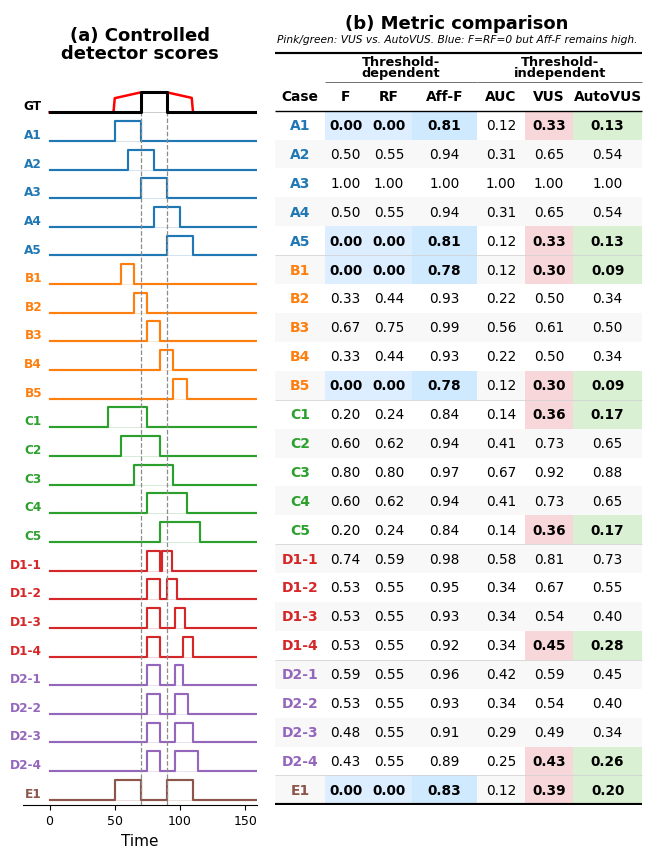

In [29]:
# -----------------------------
# Figure 13: final accepted layout
# -----------------------------
plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.titlesize": 13,
    "axes.labelsize": 11,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
})

ZITA13 = 1 / np.sqrt(2)

def vus_style_soft_label13(T, start, end, buffer, zita=ZITA13):
    y = np.zeros(T, dtype=float)

    if buffer == 0:
        y[start:end] = 1.0
        return y

    left_idx = np.arange(max(0, start - buffer), start)
    if len(left_idx) > 0:
        left_dist = start - left_idx
        y[left_idx] = 1.0 - (1.0 - zita) * left_dist / buffer

    right_idx = np.arange(end, min(T, end + buffer))
    if len(right_idx) > 0:
        right_dist = right_idx - end
        y[right_idx] = 1.0 - (1.0 - zita) * right_dist / buffer

    y[start:end] = 1.0
    return y

soft_max13 = vus_style_soft_label13(
    T13,
    GT_START13,
    GT_END13,
    GT_LEN13,
)

fig = plt.figure(figsize=(8.0, 10.15))
gs = GridSpec(
    1, 2,
    width_ratios=[0.77, 1.23],
    wspace=0.045,
    figure=fig,
)

ax = fig.add_subplot(gs[0, 0])
ax_tbl = fig.add_subplot(gs[0, 1])
ax_tbl.axis("off")

# -----------------------------
# Left panel
# -----------------------------
plot_rows13 = [("GT", "GT", gt13)] + cases13
nrows13 = len(plot_rows13)

amp13 = 0.64
gap13 = 0.92

for idx, (group, name, series) in enumerate(plot_rows13):
    ybase = (nrows13 - 1 - idx) * gap13

    if name == "GT":
        # red maximum soft buffer used by VUS
        ax.plot(
            x13,
            ybase + amp13 * soft_max13,
            color="red",
            linewidth=1.8,
            zorder=2,
        )

        # black original binary anomaly label
        ax.step(
            x13,
            ybase + amp13 * series,
            where="post",
            color="black",
            linewidth=2.2,
            zorder=3,
        )

        color = "black"
    else:
        color = group_colors13[group]
        ax.step(
            x13,
            ybase + amp13 * series,
            where="post",
            color=color,
            linewidth=1.55,
        )

    ax.hlines(
        ybase,
        0,
        T13 - 1,
        color=color,
        linewidth=0.55,
        alpha=0.25,
    )

    ax.text(
        -5.8,
        ybase + amp13 * 0.32,
        name,
        ha="right",
        va="center",
        fontsize=8.7,
        color=color,
        fontweight="bold",
    )

ax.set_xlim(-20, T13 - 1)

# Make E1 close to the bottom while keeping GT aligned with the table header rule.
gt_baseline13 = (nrows13 - 1) * gap13
y_min13 = -0.16
target_axis_y13 = 0.886
y_max13 = (gt_baseline13 - y_min13) / target_axis_y13 + y_min13
ax.set_ylim(y_min13, y_max13)

# Short dashed anomaly-boundary lines only over the score region.
line_ymin13 = y_min13
line_ymax13 = gt_baseline13 + amp13 * 1.08
for boundary in [GT_START13, GT_END13]:
    ax.vlines(
        boundary,
        line_ymin13,
        line_ymax13,
        color="0.55",
        linestyle="--",
        linewidth=0.9,
    )

ax.set_yticks([])
ax.set_xlabel("Time", labelpad=4)

# Centered two-line title, with a blank-line effect above it.
ax.set_title("")
ax.text(
    0.50, 1.018,
    "\n(a) Controlled\ndetector scores",
    transform=ax.transAxes,
    ha="center",
    va="top",
    fontsize=13,
    fontweight="bold",
    linespacing=0.95,
)

ax.grid(False)

for spine in ["top", "right", "left"]:
    ax.spines[spine].set_visible(False)


# -----------------------------
# Right table
# -----------------------------
ax_tbl.text(
    0.5, 1.012,
    "(b) Metric comparison",
    ha="center",
    va="top",
    transform=ax_tbl.transAxes,
    fontsize=13,
    fontweight="bold",
)

ax_tbl.text(
    0.5, 0.986,
    "Pink/green: VUS vs. AutoVUS. Blue: F=RF=0 but Aff-F remains high.",
    ha="center",
    va="top",
    transform=ax_tbl.transAxes,
    fontsize=7.7,
    style="italic",
)

headers = list(fig13_metrics.columns)
# expected: ["Case", "F", "RF", "Aff-F", "AUC", "VUS", "AutoVUS"]

left, right = 0.012, 0.997
top, bottom = 0.962, 0.0005
width = right - left
height = top - bottom

n_header = 2
n_data = len(fig13_metrics)
row_h = height / (n_header + n_data)

col_widths = np.array([0.115, 0.095, 0.105, 0.150, 0.110, 0.110, 0.160])
col_widths = col_widths / col_widths.sum()

x_edges = left + width * np.r_[0, np.cumsum(col_widths)]
x_centers = (x_edges[:-1] + x_edges[1:]) / 2

y_edges = top - np.arange(n_header + n_data + 1) * row_h
y_centers = (y_edges[:-1] + y_edges[1:]) / 2

# Booktabs-style horizontal rules
ax_tbl.hlines(
    y_edges[0], left, right,
    colors="black",
    linewidth=1.55,
    transform=ax_tbl.transAxes,
)
ax_tbl.hlines(
    y_edges[2], left, right,
    colors="black",
    linewidth=1.0,
    transform=ax_tbl.transAxes,
)
ax_tbl.hlines(
    y_edges[-1], left, right,
    colors="black",
    linewidth=1.55,
    transform=ax_tbl.transAxes,
)

# Group header cmidrules
ax_tbl.hlines(
    y_edges[1], x_edges[1], x_edges[4],
    colors="0.40",
    linewidth=0.65,
    transform=ax_tbl.transAxes,
)
ax_tbl.hlines(
    y_edges[1], x_edges[4], x_edges[-1],
    colors="0.40",
    linewidth=0.65,
    transform=ax_tbl.transAxes,
)

# Two-level headers
ax_tbl.text(
    (x_edges[1] + x_edges[4]) / 2,
    y_centers[0],
    "Threshold-\ndependent",
    ha="center",
    va="center",
    transform=ax_tbl.transAxes,
    fontsize=9.3,
    fontweight="bold",
    linespacing=0.84,
)

ax_tbl.text(
    (x_edges[4] + x_edges[-1]) / 2,
    y_centers[0],
    "Threshold-\nindependent",
    ha="center",
    va="center",
    transform=ax_tbl.transAxes,
    fontsize=9.3,
    fontweight="bold",
    linespacing=0.84,
)

for j, h in enumerate(headers):
    ax_tbl.text(
        x_centers[j],
        y_centers[1],
        h,
        ha="center",
        va="center",
        transform=ax_tbl.transAxes,
        fontsize=9.9,
        fontweight="bold",
    )

# Highlight settings from accepted figure
blue_cases = {"A1", "A5", "B1", "B5", "E1"}
pink_green_cases = {"A1", "A5", "B1", "B5", "C1", "C5", "D1-4", "D2-4", "E1"}

prev_group = None

for i, row in fig13_metrics.reset_index(drop=True).iterrows():
    case = row["Case"]
    y = y_centers[i + n_header]

    # subtle alternating rows
    if i % 2 == 1:
        ax_tbl.add_patch(Rectangle(
            (left, y_edges[i + n_header + 1]),
            width,
            y_edges[i + n_header] - y_edges[i + n_header + 1],
            transform=ax_tbl.transAxes,
            facecolor="0.972",
            edgecolor="none",
            zorder=-5,
        ))

    if case.startswith("D1"):
        group = "D1"
    elif case.startswith("D2"):
        group = "D2"
    else:
        group = case[0]

    if prev_group is not None and group != prev_group:
        ax_tbl.hlines(
            y_edges[i + n_header],
            left,
            right,
            colors="0.82",
            linewidth=0.55,
            transform=ax_tbl.transAxes,
        )
    prev_group = group

    case_color = group_colors13[group]

    # VUS / AutoVUS highlights
    if case in pink_green_cases:
        for col_name, facecolor in [
            ("VUS", "#f8d7da"),
            ("AutoVUS", "#d9f0d3"),
        ]:
            j = headers.index(col_name)
            ax_tbl.add_patch(Rectangle(
                (x_edges[j], y_edges[i + n_header + 1]),
                x_edges[j + 1] - x_edges[j],
                y_edges[i + n_header] - y_edges[i + n_header + 1],
                transform=ax_tbl.transAxes,
                facecolor=facecolor,
                edgecolor="none",
                zorder=-3,
            ))

    # F=RF=0 but Aff-F remains high
    if case in blue_cases:
        for col_name, facecolor in [
            ("F", "#dceeff"),
            ("RF", "#dceeff"),
            ("Aff-F", "#cfe9ff"),
        ]:
            j = headers.index(col_name)
            ax_tbl.add_patch(Rectangle(
                (x_edges[j], y_edges[i + n_header + 1]),
                x_edges[j + 1] - x_edges[j],
                y_edges[i + n_header] - y_edges[i + n_header + 1],
                transform=ax_tbl.transAxes,
                facecolor=facecolor,
                edgecolor="none",
                zorder=-2,
            ))

    for j, h in enumerate(headers):
        value = row[h]
        txt = str(value) if h == "Case" else f"{float(value):.2f}"

        text_kwargs = {
            "fontsize": 9.85,
            "ha": "center",
            "va": "center",
            "transform": ax_tbl.transAxes,
        }

        if h == "Case":
            text_kwargs.update({
                "fontsize": 10.0,
                "fontweight": "bold",
                "color": case_color,
            })

        if case in blue_cases and h in {"F", "RF", "Aff-F"}:
            text_kwargs["fontweight"] = "bold"

        if case in pink_green_cases and h in {"VUS", "AutoVUS"}:
            text_kwargs["fontweight"] = "bold"

        ax_tbl.text(
            x_centers[j],
            y,
            txt,
            **text_kwargs,
        )

save_figure(fig, "Figure13_controlled_case_study_final")
plt.show()

In [16]:
fig13_metrics.to_csv(
    OUTPUT_DIR / "Figure13_metric_table.csv",
    index=False,
)

# Figure 14

In [17]:
# -----------------------------
# Figure 14: score helpers
# -----------------------------
T14 = 180
x14 = np.arange(T14)


def gaussian14(center, amp, width):
    return amp * np.exp(-0.5 * ((x14 - center) / width) ** 2)


def label_from_intervals14(intervals):
    y = np.zeros(T14)
    for s, e in intervals:
        y[s:e] = 1.0
    return y


def normalize14(y):
    y = np.asarray(y, dtype=float)
    if y.max() > 0:
        y = y / y.max()
    return y


# ------------------------------------------------------------------
# C1 Dense anomalies
# ------------------------------------------------------------------
dense_intervals14 = [
    (35, 42),
    (48, 55),
    (62, 69),
    (76, 83),
]
dense_label14 = label_from_intervals14(dense_intervals14)

dense_s1_14 = normalize14(
    gaussian14(39, 0.95, 2.2)
    + gaussian14(52, 1.00, 2.5)
    + gaussian14(66, 0.92, 2.4)
    + gaussian14(80, 0.90, 2.4)
)

dense_s2_14 = normalize14(
    gaussian14(60, 1.00, 15.0)
)

# ------------------------------------------------------------------
# C2 Boundary-only firing
# ------------------------------------------------------------------
boundary_intervals14 = [
    (30, 40),
    (85, 95),
    (140, 150),
]
boundary_label14 = label_from_intervals14(boundary_intervals14)

boundary_s1_14 = normalize14(
    gaussian14(35, 1.00, 2.5)
    + gaussian14(90, 1.00, 2.5)
    + gaussian14(145, 1.00, 2.5)
)

boundary_s2_14 = normalize14(
    gaussian14(24, 0.95, 2.0)
    + gaussian14(46, 0.95, 2.0)
    + gaussian14(79, 0.95, 2.0)
    + gaussian14(101, 0.95, 2.0)
    + gaussian14(134, 0.95, 2.0)
    + gaussian14(156, 0.95, 2.0)
)

# ------------------------------------------------------------------
# C3 Long anomaly vs. spikes
# ------------------------------------------------------------------
mixed_intervals14 = [
    (18, 26),
    (62, 105),
    (145, 153),
]
mixed_label14 = label_from_intervals14(mixed_intervals14)

mixed_s1_14 = normalize14(
    gaussian14(83, 1.00, 19.0)
)

mixed_s2_14 = normalize14(
    gaussian14(22, 1.00, 2.1)
    + gaussian14(149, 1.00, 2.1)
)

In [18]:
# -----------------------------
# Figure 14: latest final metrics / b*
# -----------------------------
fig14_cases = [
    {
        "id": "C1",
        "title": "Dense anomalies",
        "label": dense_label14,
        "intervals": dense_intervals14,
        "S1": dense_s1_14,
        "S2": dense_s2_14,
        "b1": (3, 2, 2, 4),
        "b2": (3, 0, 0, 4),
        "metrics": pd.DataFrame(
            [
                ("S1", 0.428, 0.903, 0.689, "(3,2,2,4)"),
                ("S2", 0.615, 0.919, 0.549, "(3,0,0,4)"),
            ],
            columns=["Score", "AUC-PR", "VUS-PR", "AutoVUS", "b*"],
        ),
    },
    {
        "id": "C2",
        "title": "Boundary-only firing",
        "label": boundary_label14,
        "intervals": boundary_intervals14,
        "S1": boundary_s1_14,
        "S2": boundary_s2_14,
        "b1": (3, 2, 3),
        "b2": (9, 9, 9),
        "metrics": pd.DataFrame(
            [
                ("S1", 0.842, 0.975, 0.919, "(3,2,3)"),
                ("S2", 0.215, 0.705, 0.455, "(9,9,9)"),
            ],
            columns=["Score", "AUC-PR", "VUS-PR", "AutoVUS", "b*"],
        ),
    },
    {
        "id": "C3",
        "title": "Long anomaly vs. spikes",
        "label": mixed_label14,
        "intervals": mixed_intervals14,
        "S1": mixed_s1_14,
        "S2": mixed_s2_14,
        "b1": (0, 0, 0),
        "b2": (0, 0, 0),
        "metrics": pd.DataFrame(
            [
                ("S1", 0.861, 0.729, 0.335, "(0,0,0)"),
                ("S2", 0.606, 0.897, 0.387, "(0,0,0)"),
            ],
            columns=["Score", "AUC-PR", "VUS-PR", "AutoVUS", "b*"],
        ),
    },
]

fig14_metrics = pd.concat(
    [
        case["metrics"].assign(Case=case["id"])
        for case in fig14_cases
    ],
    ignore_index=True,
)
fig14_metrics

,Score,AUC-PR,VUS-PR,AutoVUS,b*,Case
0,S1,0.428,0.903,0.689,"(3,2,2,4)",C1
1,S2,0.615,0.919,0.549,"(3,0,0,4)",C1
2,S1,0.842,0.975,0.919,"(3,2,3)",C2
3,S2,0.215,0.705,0.455,"(9,9,9)",C2
4,S1,0.861,0.729,0.335,"(0,0,0)",C3
5,S2,0.606,0.897,0.387,"(0,0,0)",C3


saved: casestudies\autovus_requested_figures\m245_compact_polished_no_pink_background.png
saved: casestudies\autovus_requested_figures\m245_compact_polished_no_pink_background.pdf


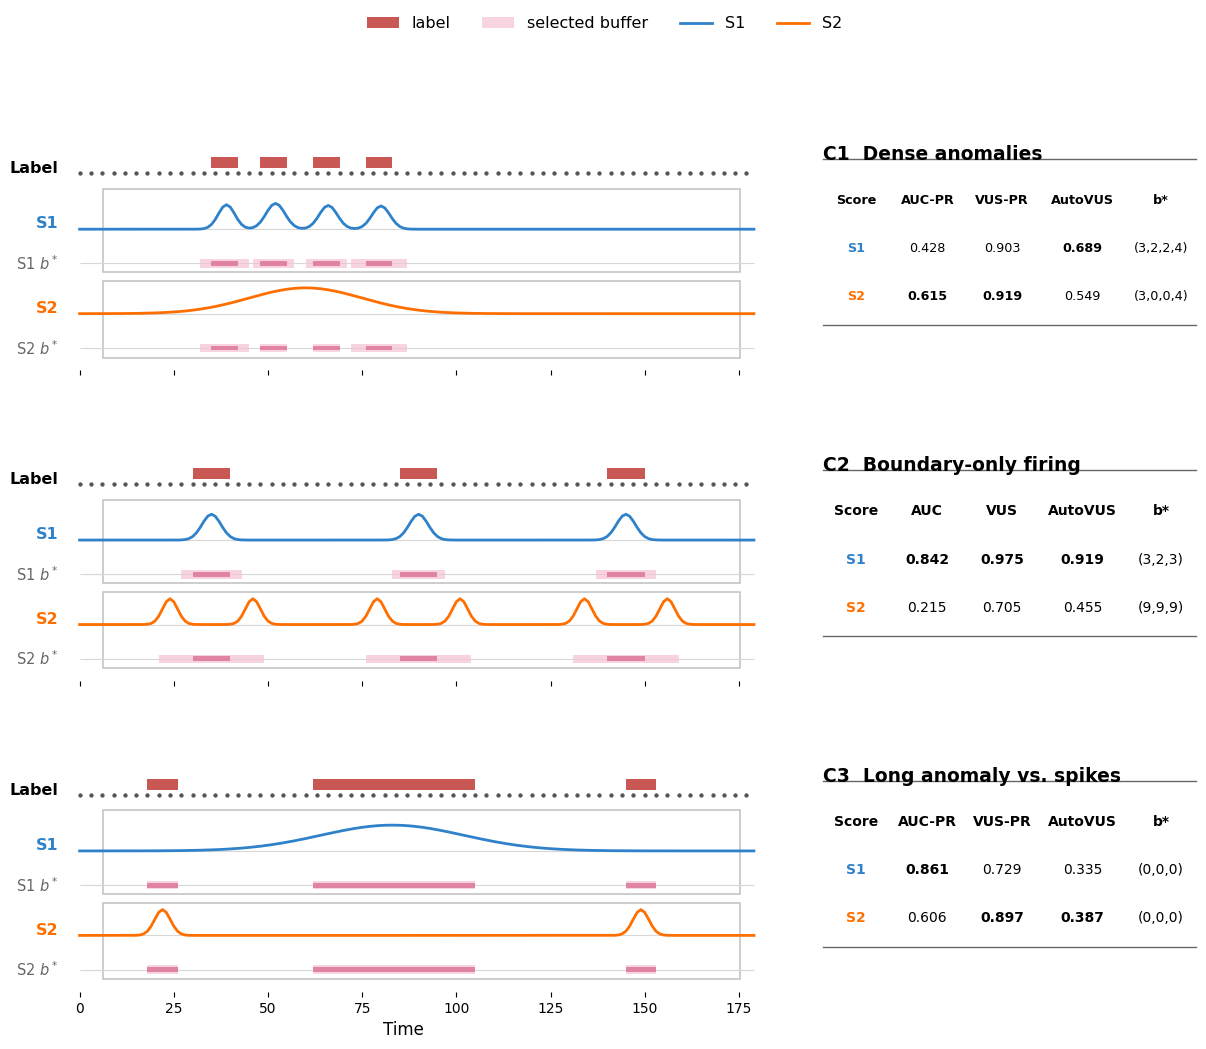

In [31]:
# -----------------------------
# Figure 14: July white-background version
# no pink background / no filled case boxes
# -----------------------------

plt.rcParams.update({
    "font.size": 12,
    "axes.titlesize": 14,
    "axes.labelsize": 12,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
})

# Palette.
C_LABEL = "#c95855"  # ground-truth red
C_BUFFER = "#f4c4d3"  # faded red / pink buffer
C_BUFFER_CORE = "#df7fa1"  # darker anomaly core inside buffer row
C_S1 = "#2f82c9"  # S1 blue
C_S2 = "#ff6f00"  # S2 orange
C_BASE = "#555555"
C_PAIR_BOX = "#bdbdbd"  # neutral outline only
C_RULE = "#666666"

fig = plt.figure(figsize=(14.8, 11.0))
outer = GridSpec(
    3, 2,
    width_ratios=[1.80, 0.95],
    hspace=0.38,
    wspace=0.12,
    figure=fig,
)


def draw_selected_buffer_row(
        ax,
        intervals,
        bvec,
        y,
        height=0.18,
):
    """
    Pale pink = selected expanded buffer.
    Darker pink = original anomaly core.
    """
    for (s, e), b in zip(intervals, bvec):
        b = int(b)
        ext_s = max(0, s - b)
        ext_e = min(T14, e + b)

        ax.add_patch(
            Rectangle(
                (ext_s, y - height / 2),
                ext_e - ext_s,
                height,
                facecolor=C_BUFFER,
                edgecolor="none",
                alpha=0.72,
                zorder=2,
            )
        )

        ax.add_patch(
            Rectangle(
                (s, y - height * 0.28),
                e - s,
                height * 0.56,
                facecolor=C_BUFFER_CORE,
                edgecolor="none",
                alpha=0.95,
                zorder=3,
            )
        )


def draw_fig14_table(ax, case):
    ax.axis("off")

    ax.text(
        0.00,
        1.00,
        f"{case['id']}  {case['title']}",
        ha="left",
        va="top",
        fontsize=13.5,
        fontweight="bold",
        transform=ax.transAxes,
    )

    ax.plot(
        [0.00, 1.00],
        [0.935, 0.935],
        transform=ax.transAxes,
        color=C_RULE,
        linewidth=1.0,
        clip_on=False,
    )

    df = case["metrics"]
    table = Table(ax, bbox=[0.00, 0.22, 1.00, 0.64])

    headers = list(df.columns)
    widths = [0.18, 0.20, 0.20, 0.23, 0.19]
    row_h = 1.0 / 3.0

    for j, h in enumerate(headers):
        cell = table.add_cell(
            0, j,
            width=widths[j],
            height=row_h,
            text=h,
            loc="center",
        )
        cell.set_facecolor("white")
        cell.set_edgecolor("none")
        cell.set_text_props(fontsize=10.0, fontweight="bold")

    for i in range(2):
        for j, h in enumerate(headers):
            val = df.iloc[i][h]

            if h in {"Score", "b*"}:
                txt = str(val)
            else:
                txt = f"{float(val):.3f}"

            cell = table.add_cell(
                i + 1, j,
                width=widths[j],
                height=row_h,
                text=txt,
                loc="center",
            )
            cell.set_facecolor("white")
            cell.set_edgecolor("none")
            cell.set_text_props(fontsize=10.2)

            if h == "Score":
                cell.set_text_props(
                    fontsize=10.4,
                    fontweight="bold",
                    color=C_S1 if i == 0 else C_S2,
                )

    # Highlight the intended winner in each case.
    if case["id"] == "C1":
        # AUC/VUS favor S2, AutoVUS favors S1.
        for col in [1, 2]:
            table[(2, col)].set_text_props(fontweight="bold")
        table[(1, 3)].set_text_props(fontweight="bold")

    elif case["id"] == "C2":
        # S1 strongly wins all three.
        for col in [1, 2, 3]:
            table[(1, col)].set_text_props(fontweight="bold")

    elif case["id"] == "C3":
        # AUC favors S1; VUS / AutoVUS favor S2.
        table[(1, 1)].set_text_props(fontweight="bold")
        for col in [2, 3]:
            table[(2, col)].set_text_props(fontweight="bold")

    ax.add_table(table)

    ax.plot(
        [0.00, 1.00],
        [0.20, 0.20],
        transform=ax.transAxes,
        color=C_RULE,
        linewidth=1.0,
        clip_on=False,
    )


for row, case in enumerate(fig14_cases):
    ax = fig.add_subplot(outer[row, 0])
    ax_table = fig.add_subplot(outer[row, 1])

    # y positions.
    y_label = 4.55
    y_s1 = 3.35
    y_b1 = 2.62
    y_s2 = 1.55
    y_b2 = 0.82

    # -------------------------------------------------------------
    # Pair boxes only: no filled pink background.
    # S1 + S1 b*, S2 + S2 b*
    # -------------------------------------------------------------
    ax.add_patch(
        Rectangle(
            (0.075, 0.435),
            0.90,
            0.37,
            transform=ax.transAxes,
            facecolor="none",
            edgecolor=C_PAIR_BOX,
            linewidth=1.1,
            alpha=0.95,
            zorder=-10,
            clip_on=False,
        )
    )

    ax.add_patch(
        Rectangle(
            (0.075, 0.055),
            0.90,
            0.34,
            transform=ax.transAxes,
            facecolor="none",
            edgecolor=C_PAIR_BOX,
            linewidth=1.1,
            alpha=0.95,
            zorder=-10,
            clip_on=False,
        )
    )

    # -------------------------------------------------------------
    # Label row: dotted baseline + red GT blocks.
    # -------------------------------------------------------------
    ax.plot(
        x14,
        np.full(T14, y_label),
        color=C_BASE,
        linewidth=0,
        marker=".",
        markersize=4.2,
        markevery=3,
        zorder=1,
    )

    for s, e in case["intervals"]:
        ax.add_patch(
            Rectangle(
                (s, y_label + 0.10),
                e - s,
                0.24,
                facecolor=C_LABEL,
                edgecolor="none",
                zorder=3,
            )
        )

    # -------------------------------------------------------------
    # S1 curve.
    # -------------------------------------------------------------
    s1 = case["S1"]
    ax.plot(
        x14,
        y_s1 + 0.55 * s1,
        color=C_S1,
        linewidth=2.0,
        zorder=5,
    )

    ax.hlines(
        y_s1,
        0,
        T14 - 1,
        color="#d7d7d7",
        linewidth=0.8,
        zorder=0,
    )

    # S1 b*
    ax.hlines(
        y_b1,
        0,
        T14 - 1,
        color="#d7d7d7",
        linewidth=0.8,
        zorder=0,
    )

    draw_selected_buffer_row(
        ax,
        case["intervals"],
        case["b1"],
        y_b1,
    )

    # -------------------------------------------------------------
    # S2 curve.
    # -------------------------------------------------------------
    s2 = case["S2"]
    ax.plot(
        x14,
        y_s2 + 0.55 * s2,
        color=C_S2,
        linewidth=2.0,
        zorder=5,
    )

    ax.hlines(
        y_s2,
        0,
        T14 - 1,
        color="#d7d7d7",
        linewidth=0.8,
        zorder=0,
    )

    # S2 b*
    ax.hlines(
        y_b2,
        0,
        T14 - 1,
        color="#d7d7d7",
        linewidth=0.8,
        zorder=0,
    )

    draw_selected_buffer_row(
        ax,
        case["intervals"],
        case["b2"],
        y_b2,
    )

    # -------------------------------------------------------------
    # Labels at left.
    # -------------------------------------------------------------
    label_x = -5.5

    ax.text(
        label_x,
        y_label + 0.10,
        "Label",
        ha="right",
        va="center",
        fontsize=11.5,
        fontweight="bold",
        color="black",
    )

    ax.text(
        label_x,
        y_s1 + 0.12,
        "S1",
        ha="right",
        va="center",
        fontsize=11.5,
        fontweight="bold",
        color=C_S1,
    )

    ax.text(
        label_x,
        y_b1,
        r"S1 $b^*$",
        ha="right",
        va="center",
        fontsize=10.5,
        color="#666666",
    )

    ax.text(
        label_x,
        y_s2 + 0.12,
        "S2",
        ha="right",
        va="center",
        fontsize=11.5,
        fontweight="bold",
        color=C_S2,
    )

    ax.text(
        label_x,
        y_b2,
        r"S2 $b^*$",
        ha="right",
        va="center",
        fontsize=10.5,
        color="#666666",
    )

    ax.set_xlim(-8, T14)
    ax.set_ylim(0.35, 5.15)
    ax.set_yticks([])

    if row == 2:
        ax.set_xlabel("Time")
    else:
        ax.tick_params(labelbottom=False)

    for spine in ["top", "right", "left", "bottom"]:
        ax.spines[spine].set_visible(False)

    ax.grid(False)

    # Right metric table.
    draw_fig14_table(ax_table, case)

# Small legend across the top.
legend_handles = [
    Patch(facecolor=C_LABEL, edgecolor="none", label="label"),
    Patch(facecolor=C_BUFFER, edgecolor="none", alpha=0.72, label="selected buffer"),
    plt.Line2D([0], [0], color=C_S1, linewidth=2.0, label="S1"),
    plt.Line2D([0], [0], color=C_S2, linewidth=2.0, label="S2"),
]

fig.legend(
    handles=legend_handles,
    frameon=False,
    ncol=4,
    loc="upper center",
    bbox_to_anchor=(0.50, 1.01),
    fontsize=11.5,
)

save_figure(fig, "m245_compact_polished_no_pink_background")
plt.show()

fig14_metrics = pd.concat(
    [
        case["metrics"].assign(Case=case["title"])
        for case in fig14_cases
    ],
    ignore_index=True,
)

fig14_metrics.to_csv(
    OUTPUT_DIR / "m245_compact_polished_no_pink_background_metrics.csv",
    index=False,
)

In [ ]:
fig14_metrics.to_csv(
    OUTPUT_DIR / "Figure14_metric_table.csv",
    index=False,
)